# Próba poprawy HOG + SVM

Zadanie ze sprintu 2: sprawdzić, czy da się poprawić HOG + SVM bez zmiany metody. Na podstawie [analizy błędów](analiza_bledow_hog_svm.ipynb) testujemy cztery kierunki:

1. **Balansowanie klas**: Car to 49% wycinków.
2. **Augmentacja**: dodatkowe kopie z losowym przycięciem i zmianą jasności.
3. **Kolor**: HOG działa na szarości, a kolor mógłby odróżnić karetki, wozy strażackie i autobusy.
4. **Kształt**: proporcje ramki, HOG bez rozciągania do kwadratu, zgrubny HOG, HOG na RGB.

Wszystkie warianty mają ten sam protokół co `src/train.py`: wycinki z train + valid, 5 foldów `StratifiedGroupKFold` z tym samym seedem, odbicia lustrzane w części uczącej i SVM z jądrem RBF. Zbiór testowy pozostaje nieużyty.

Cechy liczymy raz dla każdego wycinka, a potem tylko trenujemy SVM, dzięki czemu cały notatnik wykonuje się w kilka minut.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.feature import hog
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.config import CROPS_DIR
from src.dataset import load_crops
from src.train import N_FOLDS, RANDOM_STATE, TARGET_MACRO_F1, scores

images, labels, groups = load_crops(CROPS_DIR, ("train", "valid"))
labels = np.array(labels)
classes = [str(c) for c in sorted(set(labels))]
print(f"{len(images)} wycinków, klasy: {classes}")

894 wycinków, klasy: ['Ambulance', 'Bus', 'Car', 'Motorcycle', 'Truck']


## Cechy

- `hog`: obecne cechy z `src/features.py` (szarość, 128×128, 12 kierunków, komórki 16 px).
- `hog_rgb`: to samo na obrazie kolorowym. W każdym pikselu brany jest gradient kanału o największej sile.
- `hog_lb`: HOG bez rozciągania. Dłuższy bok skalujemy do 128 px, a krótszy dopełniamy powieleniem krawędzi, więc autobus nie zamienia się w kwadrat.
- `hog_coarse`: zgrubny HOG z 64×64, opisujący ogólną sylwetkę.
- `color`: histogram odcienia × nasycenia (8×4) i jasności (4) w HSV, z pierwiastkiem z wartości.
- `aspect`: logarytm proporcji szerokości do wysokości ramki.

In [2]:
HOG_ARGS = dict(orientations=12, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")


def gray(image, size):
    return cv2.cvtColor(cv2.resize(image, (size, size)), cv2.COLOR_BGR2GRAY)


def letterbox(image, size):
    height, width = image.shape[:2]
    scale = size / max(height, width)
    resized = cv2.resize(image, (max(1, round(width * scale)), max(1, round(height * scale))))
    h, w = resized.shape[:2]
    top, left = (size - h) // 2, (size - w) // 2
    return cv2.copyMakeBorder(resized, top, size - h - top, left, size - w - left, cv2.BORDER_REPLICATE)


def color_histogram(image):
    hsv = cv2.cvtColor(cv2.resize(image, (64, 64)), cv2.COLOR_BGR2HSV)
    hs = cv2.calcHist([hsv], [0, 1], None, [8, 4], [0, 180, 0, 256]).ravel()
    v = cv2.calcHist([hsv], [2], None, [4], [0, 256]).ravel()
    return np.sqrt(np.concatenate([hs / hs.sum(), v / v.sum()]))


EXTRACTORS = {
    "hog": lambda image: hog(gray(image, 128), **HOG_ARGS),
    "hog_rgb": lambda image: hog(cv2.resize(image, (128, 128)), channel_axis=-1, **HOG_ARGS),
    "hog_lb": lambda image: hog(cv2.cvtColor(letterbox(image, 128), cv2.COLOR_BGR2GRAY), **HOG_ARGS),
    "hog_coarse": lambda image: hog(gray(image, 64), orientations=9, pixels_per_cell=(16, 16),
                                    cells_per_block=(2, 2), block_norm="L2-Hys"),
    "color": color_histogram,
    "aspect": lambda image: np.array([np.log(image.shape[1] / image.shape[0])]),
}

rng = np.random.default_rng(0)


def augment(image):
    """Losowe przycięcie do 85–100% wymiarów oraz zmiana jasności i kontrastu."""
    height, width = image.shape[:2]
    scale = rng.uniform(0.85, 1.0)
    h, w = max(8, int(height * scale)), max(8, int(width * scale))
    y, x = rng.integers(0, height - h + 1), rng.integers(0, width - w + 1)
    crop = image[y:y + h, x:x + w].astype(np.float32) * rng.uniform(0.8, 1.2) + rng.uniform(-20, 20)
    return np.clip(crop, 0, 255).astype(np.uint8)


def compute(batch):
    return {name: np.array([extract(image) for image in batch]) for name, extract in EXTRACTORS.items()}


original = compute(images)
flipped = compute([cv2.flip(image, 1) for image in images])
augmented = [compute([augment(image) for image in images]),
             compute([augment(cv2.flip(image, 1)) for image in images])]
print({name: block.shape[1] for name, block in original.items()})

{'hog': 2352, 'hog_rgb': 2352, 'hog_lb': 2352, 'hog_coarse': 324, 'color': 36, 'aspect': 1}


## Walidacja krzyżowa

Gdy łączymy bloki cech, po standaryzacji mnożymy każdy dodatkowy blok tak, żeby jego łączna wariancja wynosiła `waga × liczba cech pierwszego bloku`. Bez tego 37 cech koloru zginęłoby wśród 2352 cech HOG, a pojedyncza cecha proporcji tym bardziej.

In [3]:
results = []


def evaluate(name, blocks, extra=(), C=1, gamma="auto", class_weight="balanced",
             oversample=False, seed=RANDOM_STATE, group="", record=True):
    training_sets = [original, flipped, *extra]
    reference = original[blocks[0][0]].shape[1]
    weights = np.concatenate([
        np.full(original[b].shape[1], 1.0 if i == 0 else np.sqrt(w * reference / original[b].shape[1]))
        for i, (b, w) in enumerate(blocks)])
    sampler = np.random.default_rng(seed)
    predicted = np.empty_like(labels)
    folds = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    for train_index, test_index in folds.split(labels, labels, groups):
        if oversample:
            # dolosowujemy przykłady rzadszych klas do liczności najliczniejszej klasy
            largest = max((labels[train_index] == c).sum() for c in classes)
            train_index = np.concatenate([
                np.concatenate([idx, sampler.choice(idx, largest - len(idx))])
                for idx in (train_index[labels[train_index] == c] for c in classes)])
        X = np.vstack([np.hstack([s[b][train_index] for b, _ in blocks]) for s in training_sets])
        y = np.concatenate([labels[train_index]] * len(training_sets))
        scaler = StandardScaler().fit(X)
        model = SVC(C=C, gamma=gamma, class_weight=class_weight).fit(scaler.transform(X) * weights, y)
        X_test = np.hstack([original[b][test_index] for b, _ in blocks])
        predicted[test_index] = model.predict(scaler.transform(X_test) * weights)
    accuracy, macro_f1, recalls = scores(labels, predicted, classes)
    row = {"grupa": group, "wariant": name, "accuracy": accuracy, "macro F1": macro_f1,
           **{f"recall {c}": r for c, r in zip(classes, recalls)}}
    if record:
        results.append(row)
    return row


def show(group):
    table = pd.DataFrame([r for r in results if r["grupa"] in ("", group)]).drop(columns="grupa")
    return table.set_index("wariant").style.format("{:.3f}").background_gradient(
        subset=["macro F1"], cmap="Greens")


HOG = [("hog", 1)]
evaluate("HOG + SVM (obecny model)", HOG)
show("")

,accuracy,macro F1,recall Ambulance,recall Bus,recall Car,recall Motorcycle,recall Truck
wariant,,,,,,,
HOG + SVM (obecny model),0.742,0.680,0.670,0.652,0.871,0.769,0.388


## 1. Balansowanie klas

Obecny model już używa `class_weight="balanced"`, czyli przy rzadszych klasach błąd kosztuje więcej. Porównujemy go z wariantem bez wag oraz z oversamplingiem, czyli dolosowaniem kopii przykładów rzadszych klas do liczności klasy Car.

In [4]:
evaluate("bez class_weight", HOG, class_weight=None, group="balans")
# Po dolosowaniu klasy są równoliczne, więc class_weight="balanced" i tak dałby wagi 1
evaluate("oversampling", HOG, class_weight=None, oversample=True, group="balans")
show("balans")

,accuracy,macro F1,recall Ambulance,recall Bus,recall Car,recall Motorcycle,recall Truck
wariant,,,,,,,
HOG + SVM (obecny model),0.742,0.680,0.670,0.652,0.871,0.769,0.388
bez class_weight,0.732,0.642,0.591,0.607,0.954,0.641,0.250
oversampling,0.744,0.666,0.617,0.634,0.935,0.684,0.319


## 2. Augmentacja

Do odbić lustrzanych dokładamy dwie kopie każdego wycinka uczącego z losowym przycięciem i zmianą jasności. Jedna kopia jest z oryginału, druga z odbicia.

In [5]:
evaluate("+ 2 kopie (przycięcie, jasność)", HOG, extra=augmented, group="augmentacja")
show("augmentacja")

,accuracy,macro F1,recall Ambulance,recall Bus,recall Car,recall Motorcycle,recall Truck
wariant,,,,,,,
HOG + SVM (obecny model),0.742,0.680,0.670,0.652,0.871,0.769,0.388
"+ 2 kopie (przycięcie, jasność)",0.730,0.665,0.678,0.634,0.859,0.761,0.362


## 3. Kolor

Histogram koloru dołączony do HOG z różną wagą.

In [6]:
for weight in (0.1, 0.25, 0.5, 1.0):
    evaluate(f"HOG + kolor, waga {weight}", HOG + [("color", weight)], group="kolor")
evaluate("HOG + kolor 0.1, gamma='scale'", HOG + [("color", 0.1)], gamma="scale", group="kolor")
show("kolor")

,accuracy,macro F1,recall Ambulance,recall Bus,recall Car,recall Motorcycle,recall Truck
wariant,,,,,,,
HOG + SVM (obecny model),0.742,0.680,0.670,0.652,0.871,0.769,0.388
"HOG + kolor, waga 0.1",0.748,0.691,0.704,0.661,0.880,0.744,0.388
"HOG + kolor, waga 0.25",0.737,0.669,0.670,0.643,0.892,0.726,0.328
"HOG + kolor, waga 0.5",0.723,0.649,0.635,0.589,0.906,0.675,0.302
"HOG + kolor, waga 1.0",0.683,0.600,0.565,0.491,0.910,0.564,0.259
"HOG + kolor 0.1, gamma='scale'",0.752,0.696,0.722,0.679,0.873,0.752,0.397


## 4. Kształt

In [7]:
for weight in (0.05, 0.25):
    evaluate(f"HOG + proporcje ramki, waga {weight}", HOG + [("aspect", weight)], group="kształt")
evaluate("HOG bez rozciągania (letterbox)", [("hog_lb", 1)], group="kształt")
evaluate("HOG + zgrubny HOG, waga 0.25", HOG + [("hog_coarse", 0.25)], group="kształt")
evaluate("HOG na RGB", [("hog_rgb", 1)], group="kształt")
show("kształt")

,accuracy,macro F1,recall Ambulance,recall Bus,recall Car,recall Motorcycle,recall Truck
wariant,,,,,,,
HOG + SVM (obecny model),0.742,0.680,0.670,0.652,0.871,0.769,0.388
"HOG + proporcje ramki, waga 0.05",0.734,0.671,0.643,0.634,0.862,0.795,0.379
"HOG + proporcje ramki, waga 0.25",0.728,0.661,0.635,0.616,0.864,0.786,0.362
HOG bez rozciągania (letterbox),0.709,0.641,0.609,0.625,0.823,0.795,0.379
"HOG + zgrubny HOG, waga 0.25",0.742,0.680,0.661,0.634,0.878,0.735,0.422
HOG na RGB,0.744,0.682,0.722,0.625,0.869,0.761,0.397


## 5. Czy poprawa jest prawdziwa?

Różnice rzędu 0,01 mogą wynikać z przypadkowego podziału na foldy. Najlepsze warianty sprawdzamy więc na 5 różnych podziałach (różne seedy) i porównujemy każdy z obecnym modelem przy **tym samym** podziale.

In [8]:
candidates = {
    "HOG + SVM (obecny model)": dict(blocks=HOG),
    "HOG + kolor 0.1, gamma='scale'": dict(blocks=HOG + [("color", 0.1)], gamma="scale"),
    "HOG na RGB": dict(blocks=[("hog_rgb", 1)]),
}
seeds = [RANDOM_STATE, 0, 1, 2, 3]
f1 = {name: np.array([evaluate(name, seed=s, record=False, **kw)["macro F1"] for s in seeds])
      for name, kw in candidates.items()}

base = f1["HOG + SVM (obecny model)"]
stability = pd.DataFrame({
    "średni macro F1": {n: v.mean() for n, v in f1.items()},
    "odchylenie": {n: v.std() for n, v in f1.items()},
    "zmiana vs obecny": {n: (v - base).mean() for n, v in f1.items()},
    "lepszy w podziałach": {n: f"{(v > base).sum()}/{len(seeds)}" for n, v in f1.items()},
})
stability.style.format({"średni macro F1": "{:.3f}", "odchylenie": "{:.3f}", "zmiana vs obecny": "{:+.3f}"})

,średni macro F1,odchylenie,zmiana vs obecny,lepszy w podziałach
HOG + SVM (obecny model),0.680,0.002,+0.000,0/5
"HOG + kolor 0.1, gamma='scale'",0.680,0.010,-0.000,2/5
HOG na RGB,0.686,0.004,+0.006,5/5


## Podsumowanie

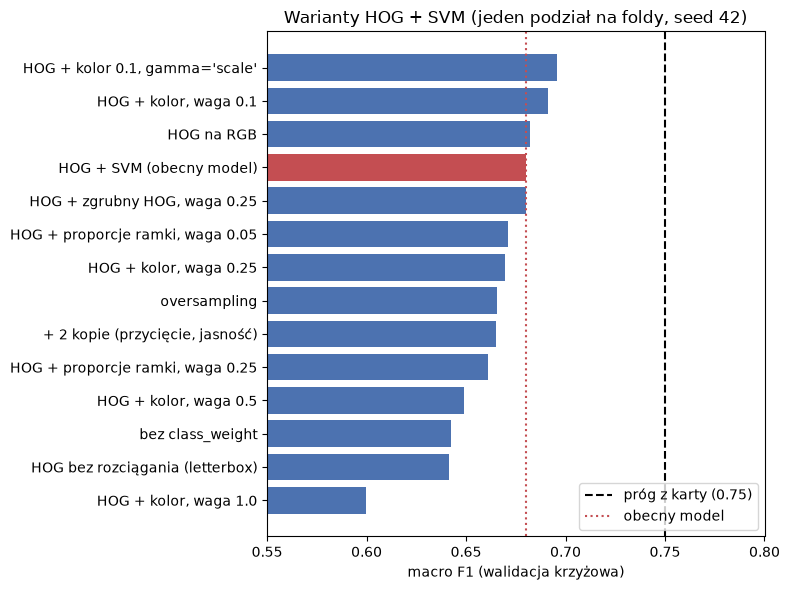

In [9]:
summary = pd.DataFrame(results).sort_values("macro F1")
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#C44E52" if n.startswith("HOG + SVM (obecny") else "#4C72B0" for n in summary["wariant"]]
ax.barh(summary["wariant"], summary["macro F1"], color=colors)
ax.axvline(TARGET_MACRO_F1, color="black", linestyle="--", label=f"próg z karty ({TARGET_MACRO_F1})")
ax.axvline(summary.loc[summary["wariant"] == "HOG + SVM (obecny model)", "macro F1"].item(),
           color="#C44E52", linestyle=":", label="obecny model")
ax.set_xlim(0.55, 0.8)
ax.set_xlabel("macro F1 (walidacja krzyżowa)")
ax.set_title("Warianty HOG + SVM (jeden podział na foldy, seed 42)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Wnioski

**Żadna z prób nie zbliża HOG + SVM do progu z karty.** Najlepsze warianty osiągają macro F1 około 0,69–0,70 przy jednym podziale na foldy, a próg to 0,75. Recall Truck nigdzie nie przekracza 0,42.

**1. Balansowanie: obecne `class_weight="balanced"` jest najlepsze.** Bez wag F1 spada do 0,642, a recall Truck do 0,25, bo model zaczyna faworyzować klasę Car. Oversampling (0,666) też wypada gorzej niż wagi. Nierówne klasy są więc już rozwiązane, a słaby wynik Truck nie wynika z liczby przykładów, bo Truck ma ich tyle co Bus, Ambulance i Motorcycle.

**2. Augmentacja nie pomaga** (0,665 wobec 0,680). Prawdopodobnie przycięcie usuwa fragment sylwetki, na której opiera się HOG, a odbicia lustrzane już dają potrzebną różnorodność.

**3. Kolor tylko pozornie pomaga.** Przy wadze 0,1 jeden podział daje +0,016, ale na 5 podziałach średnia zmiana wynosi 0,000, a wariant wygrywa tylko w 2 z 5. Ten zysk to przypadek. Przy większej wadze wynik wyraźnie spada (waga 1,0 → 0,600). Histogram całego wycinka obejmuje tło, a samochody i ciężarówki mają dowolne kolory, więc kolor wprowadza więcej szumu niż informacji.

**4. Kształt:**
- Proporcje ramki nie pomagają (0,671 i 0,661).
- HOG bez rozciągania jest wyraźnie gorszy (0,641). Rozciąganie do kwadratu nie jest więc problemem. Przy dopełnianiu pojazd zajmuje mniej komórek HOG, więc opisuje go mniej cech.
- Zgrubny HOG nie zmienia wyniku (0,680). Podnosi recall Truck do 0,42, ale obniża recall innych klas.
- **HOG na RGB to jedyna zmiana, która pomaga konsekwentnie:** średnio +0,006 F1, lepiej we wszystkich 5 podziałach. Zysk jest jednak za mały, żeby miał praktyczne znaczenie.

### Rekomendacja

- **Nie zmieniamy obecnego modelu.** HOG na RGB można ewentualnie przyjąć jako drobną, bezpieczną poprawkę (jeden parametr `channel_axis` w `HogTransformer`), ale nie zmienia ona obrazu sytuacji.
- **HOG + SVM osiąga na tych danych sufit około 0,68–0,69 macro F1.** Do spełnienia progów z karty potrzebne są inne cechy albo doprecyzowanie klasy Truck (pickupy, patrz analiza błędów). Plan awaryjny, czyli MobileNet + SVM dodany do `src/train.py`, daje w tym samym protokole macro F1 0,834 przy `C=1`. Nadal jednak nie spełnia progu recall dla Truck: 0,59 przy `C=1` i 0,68 przy `C=0.3`.
- Uwaga metodologiczna: wiele wariantów testowaliśmy na tych samych foldach, więc najlepszy wynik z jednego podziału jest zawyżony. Dlatego obiecujące warianty sprawdziliśmy jeszcze na 5 różnych podziałach.